<div style="text-align:center;background:#d9c9f0; color:#3b2a5c; padding:30px; border-radius:8px">

<h1><b>Regresión Lineal Múltiple</b></h1>
<h3>Predicción de la Tasa de Supervivencia</h3>
<hr style="border:1px solid #8e72b8; width:60%">
<h4>Integrantes del equipo</h4>

<table style="margin:auto; border:none; color:#3b2a5c; font-size:16px;">
<tr>
<td style="border:none; padding:6px 24px;">Mariana Castrejón Pulido</td>
<td style="border:none; padding:6px 24px;">Pamela Muñoz Villar</td>
<td style="border:none; padding:6px 24px;">Fabricio Condes Ballesteros</td>
</tr>
<tr>
<td style="border:none; padding:6px 24px;">Kevin Scott Rodrigues Moreno</td>
<td style="border:none; padding:6px 24px;">Sergio Yahir Hernández Guerrero</td>
<td style="border:none; padding:6px 24px;">Emmanuel Paduano Flores</td>
</tr>
</table>

</div>

<div style="background:#f1f8f4; color:black; padding:25px 35px; border-left:8px solid #2e7d4f; border-radius:6px; text-align:left;">

<h2 style="color:#2e7d4f; margin-top:0;"><b>ÍNDICE</b></h2>
<hr style="border:1px solid #a5d6b7;">

[<span style="color:#1b5e3b; font-size:19px;"><b>1. Conjunto de datos</b></span>](#1-conjunto-de-datos)

[<span style="color:#1b5e3b; font-size:19px;"><b>2. Importación de librerías</b></span>](#2-importación-de-librerías)

[<span style="color:#1b5e3b; font-size:19px;"><b>3. Preprocesamiento de datos</b></span>](#3-preprocesamiento-de-datos)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.1. Valores nulos</span>](#31-valores-nulos)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.2. Duplicados</span>](#32-duplicados)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.3. Tipos de datos</span>](#33-tipos-de-datos)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[<span style="color:#1b5e3b; font-size:16px;">3.4. Escalado</span>](#34-escalado)

[<span style="color:#1b5e3b; font-size:19px;"><b>4. Modelado: regresión lineal múltiple</b></span>](#4-modelado-regresión-lineal-múltiple)

[<span style="color:#1b5e3b; font-size:19px;"><b>5. Predicciones</b></span>](#5-predicciones)

[<span style="color:#1b5e3b; font-size:19px;"><b>6. Métricas de evaluación</b></span>](#6-métricas-de-evaluación)

[<span style="color:#1b5e3b; font-size:19px;"><b>7. Gráfica de valores reales contra predichos</b></span>](#7-gráfica-de-valores-reales-contra-predichos)

[<span style="color:#1b5e3b; font-size:19px;"><b>8. Predicción para un nuevo paciente</b></span>](#8-predicción-para-un-nuevo-paciente)

[<span style="color:#1b5e3b; font-size:19px;"><b>9. Conclusiones</b></span>](#9-conclusiones)

</div>



<a id="obtencion"></a>

<div style="background:#f8c8dc; color:#5a1a33; padding:10px 20px; border-radius:6px">

## 1. Conjunto de datos

</div>

---

El proyecto utiliza el archivo `Conjunto_de _datos.csv`, con **10 registros** y **4 columnas**, ubicado en la misma carpeta que este documento.

### Metadatos: descripción de cada columna

| Columna | Significado | Tipo | Papel en el modelo |
| :--- | :--- | :--- | :--- |
| `ID_Paciente` | Identificador único de cada paciente | Entero | No se usa (se elimina) |
| `Edad` | Edad del paciente | Entero | Variable independiente $X_1$ |
| `Tamaño_Tumor` | Tamaño del tumor del paciente | Decimal | Variable independiente $X_2$ |
| `Tasa_de_Supervivencia` | Tasa de supervivencia del paciente | Decimal | Variable dependiente $y$ |

### Variables del modelo

* **Variables independientes ($X$):** `Edad` ($X_1$) y `Tamaño_Tumor` ($X_2$).
* **Variable dependiente ($y$):** `Tasa_de_Supervivencia`. En el código se llama `Y`.

---

<a id="librerias"></a>

<div style="background:#fff3b0; color:#5c4a00; padding:10px 20px; border-radius:6px">

## 2. Importación de librerías

</div>

---

**Importar librerías** consiste en cargar módulos de código ya escritos para usar sus funciones. Se utiliza la palabra clave `import` al inicio del script, y `from` cuando solo se necesita un módulo o clase específica.

**Librerías utilizadas en este proyecto:**

* `pathlib.Path`: manejo de rutas de archivos.
* `numpy`: operaciones matemáticas y manejo de vectores/matrices (se usa para resolver la regresión).
* `pandas`: manipulación y análisis de datos en tablas (DataFrames).
* `matplotlib.pyplot`: creación de gráficas.

---

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carga del conjunto de datos
CARPETA = Path.cwd()
RUTA_CSV = CARPETA / "Conjunto_de _datos.csv"
datos = pd.read_csv(RUTA_CSV)
datos.columns = datos.columns.str.strip()

print("CONJUNTO DE DATOS ORIGINAL")
print(datos)
print(f"\nTotal de registros: {datos.shape[0]}")
print(f"Total de columnas: {datos.shape[1]}")
print(f"Columnas: {list(datos.columns)}")



CONJUNTO DE DATOS ORIGINAL
   ID_Paciente  Edad  Tamaño_Tumor  Tasa_de_Supervivencia
0            1    73      5.375612              51.312579
1            2    26      4.847098              46.373273
2            3    31      5.588391              47.072221
3            4    29      1.436600              51.853634
4            5    54      2.417506              54.708987
5            6    32      1.256500              49.458796
6            7    28      1.105990              47.196548
7            8    29      1.436600              51.853634
8            9    50           NaN              46.259842
9           10    63     49.000000              49.631189

Total de registros: 10
Total de columnas: 4
Columnas: ['ID_Paciente', 'Edad', 'Tamaño_Tumor', 'Tasa_de_Supervivencia']


<a id="preprocesamiento"></a>

<div style="background:#d9c9f0; color:#3b2a5c; padding:10px 20px; border-radius:6px">

## 3. Preprocesamiento de datos

</div>

---

Antes de crear el modelo, los datos deben estar limpios. Primero se elimina `ID_Paciente`, que solo identifica al paciente y no aporta información para predecir. Con `errors="ignore"` no hay error si la columna no existe, y con `inplace=True` el cambio se aplica directamente al DataFrame.

---

In [ ]:
# Eliminamos el identificador porque no aporta información al modelo.
df_Datos = datos.copy()
df_Datos = df_Datos.drop(columns=["ID_Paciente"], errors="ignore")

print("\nINFORMACIÓN DE LOS DATOS")
df_Datos.info()




INFORMACIÓN DE LOS DATOS
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Edad                   10 non-null     int64  
 1   Tamaño_Tumor           9 non-null      float64
 2   Tasa_de_Supervivencia  10 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 372.0 bytes


<a id="nulos"></a>

### 3.1. Valores nulos

El paciente 9 no tiene `Tamaño_Tumor`, por lo que su fila se elimina (1 valor nulo). Una fila incompleta no se puede usar en el cálculo del modelo.

In [ ]:
# Eliminamos registros con valores nulos.
nulos = int(df_Datos.isnull().sum().sum())
if nulos > 0:
    ids_nulos = datos.loc[df_Datos.index[df_Datos.isnull().any(axis=1)], "ID_Paciente"].tolist()
    df_Datos = df_Datos.dropna()
    print(f"\nSe encontraron {nulos} valores nulos; se eliminaron las filas correspondientes (paciente(s): {ids_nulos}).")
else:
    print("\nNo se encontraron valores nulos.")


Se encontraron 1 valores nulos; se eliminaron las filas correspondientes (paciente(s): [9]).


<a id="duplicados"></a>

### 3.2. Duplicados

Los pacientes 4 y 8 tienen exactamente los mismos valores (Edad 29, Tamaño 1.4366, Tasa 51.853634). Una vez quitado el ID, se detecta 1 fila duplicada y se elimina, para que un mismo dato no pese doble en el modelo.

In [ ]:
# Eliminamos filas duplicadas después de quitar el identificador.
repetidos = int(df_Datos.duplicated().sum())
if repetidos > 0:
    ids_repetidos = datos.loc[df_Datos.index[df_Datos.duplicated()], "ID_Paciente"].tolist()
    df_Datos = df_Datos.drop_duplicates()
    print(f"Se encontraron {repetidos} filas duplicadas; fueron eliminadas (paciente(s): {ids_repetidos}).")
else:
    print("No se encontraron filas duplicadas.")

Se encontraron 1 filas duplicadas; fueron eliminadas (paciente(s): [8]).


<a id="tipos"></a>

### 3.3. Tipos de datos

Se comprueba que existan las columnas `Edad`, `Tamaño_Tumor` y `Tasa_de_Supervivencia`, y que sean numéricas (`pd.to_numeric`). También se exige un mínimo de 4 registros válidos para ajustar el modelo.

In [ ]:
# Verificamos que existan las columnas necesarias.
columnas_modelo = ["Edad", "Tamaño_Tumor", "Tasa_de_Supervivencia"]
faltantes = [col for col in columnas_modelo if col not in df_Datos.columns]
if faltantes:
    raise ValueError(f"Faltan columnas requeridas en el CSV: {faltantes}")

# Aseguramos que las variables sean numéricas.
for col in columnas_modelo:
    df_Datos[col] = pd.to_numeric(df_Datos[col], errors="coerce")

df_Datos = df_Datos.dropna(subset=columnas_modelo)

if len(df_Datos) < 4:
    raise ValueError("Se necesitan al menos cuatro registros válidos para este ejemplo.")

print("\nTIPOS DE DATOS")
print(df_Datos.dtypes)

print("\nDATOS LIMPIOS")
print(df_Datos)
print(f"Registros utilizados: {len(df_Datos)}")


TIPOS DE DATOS
Edad                       int64
Tamaño_Tumor             float64
Tasa_de_Supervivencia    float64
dtype: object

DATOS LIMPIOS
   Edad  Tamaño_Tumor  Tasa_de_Supervivencia
0    73      5.375612              51.312579
1    26      4.847098              46.373273
2    31      5.588391              47.072221
3    29      1.436600              51.853634
4    54      2.417506              54.708987
5    32      1.256500              49.458796
6    28      1.105990              47.196548
9    63     49.000000              49.631189
Registros utilizados: 8


<a id="escalado"></a>

### 3.4. Escalado

El **escalado** (estandarización) transforma cada variable para que tenga media 0 y desviación estándar 1:

$$z = \frac{x - \bar{x}}{s}$$

Sirve para comparar variables con escalas muy distintas (aquí, `Edad` y `Tamaño_Tumor`). En este proyecto el modelo se calcula con las variables originales: en regresión lineal por mínimos cuadrados el escalado no cambia las predicciones ni el R², y así los coeficientes se interpretan directamente en las unidades originales.

In [ ]:
# Escalado (estandarización): media 0 y desviación estándar 1.
columnas_X = ["Edad", "Tamaño_Tumor"]
X_original = df_Datos[columnas_X]
X_escalado = (X_original - X_original.mean()) / X_original.std()

print("\nMEDIA Y DESVIACIÓN ESTÁNDAR ORIGINALES")
print(X_original.agg(["mean", "std"]).round(4))

print("\nDATOS ESCALADOS (media 0, desviación 1)")
print(X_escalado.round(4))


MEDIA Y DESVIACIÓN ESTÁNDAR ORIGINALES
         Edad  Tamaño_Tumor
mean  42.0000        8.8785
std   18.4701       16.3214

DATOS ESCALADOS (media 0, desviación 1)
     Edad  Tamaño_Tumor
0  1.6784       -0.2146
1 -0.8663       -0.2470
2 -0.5956       -0.2016
3 -0.7038       -0.4560
4  0.6497       -0.3959
5 -0.5414       -0.4670
6 -0.7580       -0.4762
9  1.1370        2.4582


<a id="modelado"></a>

<div style="background:#c5e1f5; color:#1f3d5c; padding:10px 20px; border-radius:6px">

## 4. Modelado: regresión lineal múltiple

</div>

---

La **regresión lineal múltiple** predice una variable $Y$ a partir de dos o más variables independientes. Con dos variables, la ecuación es:

$$Y = b_0 + b_1 X_1 + b_2 X_2$$

* $b_0$ es el **intercepto**: el valor de $Y$ cuando $X_1 = X_2 = 0$.
* $b_1$ y $b_2$ son los **coeficientes**: cuánto cambia $Y$ por cada unidad que aumentan la edad o el tamaño del tumor.

Los coeficientes se calculan con el **método de mínimos cuadrados**, que minimiza la suma de los errores al cuadrado:

$$\beta = (X^T X)^{-1} X^T Y$$

Se agrega una **columna de unos** a la matriz $X$ para poder calcular el intercepto $b_0$, y `np.linalg.lstsq()` resuelve el cálculo.

---

In [ ]:
# X1 = Edad, X2 = Tamaño del tumor, Y = Tasa de supervivencia.
X = df_Datos[["Edad", "Tamaño_Tumor"]].to_numpy(dtype=float)
Y = df_Datos["Tasa_de_Supervivencia"].to_numpy(dtype=float)

# La primera columna de unos permite calcular el intercepto b0.
X_matriz = np.column_stack((np.ones(len(X)), X))

# Método de mínimos cuadrados.
coeficientes, residuos, rango, valores_singulares = np.linalg.lstsq(
    X_matriz, Y, rcond=None
)

b0, b1, b2 = coeficientes

print("\nRESULTADOS DE LA REGRESIÓN LINEAL MÚLTIPLE")
print(f"Intercepto (b0): {b0:.6f}")
print(f"Coeficiente de Edad (b1): {b1:.6f}")
print(f"Coeficiente de Tamaño del tumor (b2): {b2:.6f}")
print("\nEcuación del modelo:")
print(f"Y = {b0:.6f} + ({b1:.6f} * X1) + ({b2:.6f} * X2)")


RESULTADOS DE LA REGRESIÓN LINEAL MÚLTIPLE
Intercepto (b0): 45.510250
Coeficiente de Edad (b1): 0.114825
Coeficiente de Tamaño del tumor (b2): -0.071184

Ecuación del modelo:
Y = 45.510250 + (0.114825 * X1) + (-0.071184 * X2)


<a id="predicciones"></a>

<div style="background:#ffd9b8; color:#6b3a10; padding:10px 20px; border-radius:6px">

## 5. Predicciones

</div>

---

Con los coeficientes calculados, se obtienen las **predicciones** multiplicando la matriz $X$ por el vector de coeficientes:

$$\hat{y} = X \cdot \beta$$

Después se calcula el **error** de cada registro como la diferencia entre el valor real y el predicho:

$$Error = y - \hat{y}$$

---

In [ ]:
Y_pred = X_matriz @ coeficientes

resultados = df_Datos.copy()
resultados["Tasa_Predicha"] = Y_pred
resultados["Error"] = resultados["Tasa_de_Supervivencia"] - Y_pred

print("\nCOMPARACIÓN: VALORES REALES Y PREDICHOS")
print(resultados.to_string(index=False))


COMPARACIÓN: VALORES REALES Y PREDICHOS
 Edad  Tamaño_Tumor  Tasa_de_Supervivencia  Tasa_Predicha     Error
   73      5.375612              51.312579      53.509834 -2.197255
   26      4.847098              46.373273      48.150669 -1.777396
   31      5.588391              47.072221      48.672027 -1.599806
   29      1.436600              51.853634      48.737919  3.115715
   54      2.417506              54.708987      51.538725  3.170262
   32      1.256500              49.458796      49.095215  0.363581
   28      1.105990              47.196548      48.646628 -1.450080
   63     49.000000              49.631189      49.256211  0.374978


<a id="metricas"></a>

<div style="background:#e2efb5; color:#3d4d12; padding:10px 20px; border-radius:6px">

## 6. Métricas de evaluación

</div>

---

Las **métricas de evaluación** indican qué tan bien se ajusta el modelo a los datos.

| Métrica | Fórmula | Interpretación |
| :--- | :--- | :--- |
| 🔹 **R²** | $R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$ | Proporción de la variación de $y$ que explica el modelo. Mientras más cercano a 1, mejor. |
| 🔹 **MAE** | $\frac{1}{n}\sum \lvert y - \hat{y} \rvert$ | Error promedio en las mismas unidades de $y$. |
| 🔹 **RMSE** | $\sqrt{\frac{1}{n}\sum (y - \hat{y})^2}$ | Error promedio que penaliza más los errores grandes. |

---

In [ ]:
ss_res = np.sum((Y - Y_pred) ** 2)
ss_tot = np.sum((Y - np.mean(Y)) ** 2)

r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else float("nan")
mae = np.mean(np.abs(Y - Y_pred))
rmse = np.sqrt(np.mean((Y - Y_pred) ** 2))

print("\nMÉTRICAS DEL MODELO")
print(f"R²   : {r2:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")


MÉTRICAS DEL MODELO
R²   : 0.4229
MAE  : 1.7561
RMSE : 2.0211


<a id="grafica"></a>

<div style="background:#c9ecd9; color:#1f4d37; padding:10px 20px; border-radius:6px">

## 7. Gráfica de valores reales contra predichos

</div>

---

La gráfica compara la tasa de supervivencia **real** (eje X) contra la **predicha** (eje Y). Cada punto es un registro, y la **línea punteada** representa la predicción perfecta: mientras más cerca estén los puntos de ella, mejor es el modelo.

---

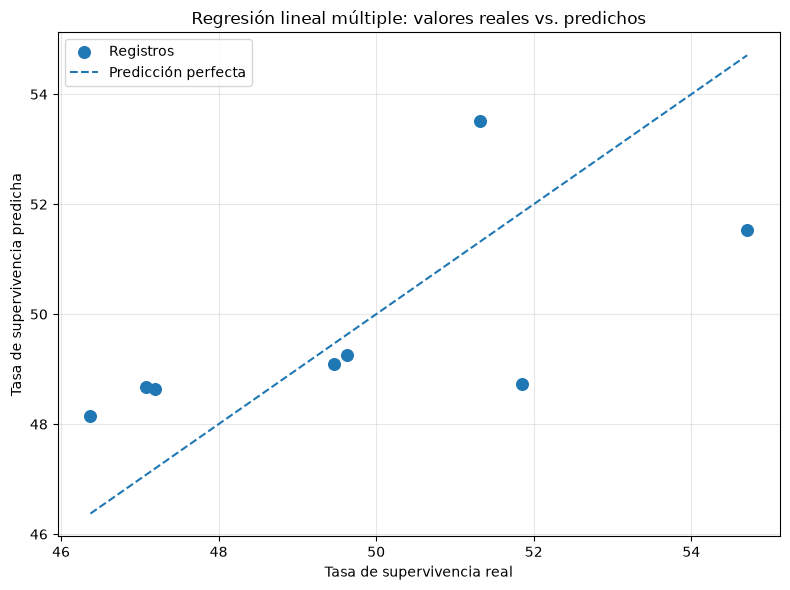

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(Y, Y_pred, label="Registros", s=70)

limite_min = min(float(np.min(Y)), float(np.min(Y_pred)))
limite_max = max(float(np.max(Y)), float(np.max(Y_pred)))
plt.plot([limite_min, limite_max], [limite_min, limite_max],
         linestyle="--", label="Predicción perfecta")

plt.xlabel("Tasa de supervivencia real")
plt.ylabel("Tasa de supervivencia predicha")
plt.title("Regresión lineal múltiple: valores reales vs. predichos")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CARPETA / "grafica_regresion_multiple.png", dpi=150)
plt.show()

<a id="nuevo"></a>

<div style="background:#f9c9c4; color:#6b1f1a; padding:10px 20px; border-radius:6px">

## 8. Predicción para un nuevo paciente

</div>

---

El programa pide al usuario la edad y el tamaño del tumor, y aplica la ecuación del modelo para mostrar la tasa de supervivencia estimada. Si se escribe algo que no sea un número, muestra un mensaje de error en lugar de detenerse.

**Ejemplo:** para un paciente de 40 años con tumor de tamaño 3:

$$Y = 45.5103 + (0.1148 \cdot 40) + (-0.0712 \cdot 3) \approx 49.89$$


---

In [ ]:
print("\nPREDICCIÓN PARA UN NUEVO PACIENTE")
try:
    edad = float(40)
    tamano_tumor = float(3)

    prediccion = b0 + b1 * edad + b2 * tamano_tumor
    print(f"Tasa de supervivencia estimada por el modelo: {prediccion:.2f}")
except ValueError:
    print("No se realizó la predicción: debes ingresar valores numéricos.")

print("\nProceso terminado.")
print("NOTA: Este conjunto pequeño es únicamente para fines académicos.")
print("El modelo no debe utilizarse para decisiones ni predicciones clínicas reales.")


PREDICCIÓN PARA UN NUEVO PACIENTE
Tasa de supervivencia estimada por el modelo: 49.89

Proceso terminado.
NOTA: Este conjunto pequeño es únicamente para fines académicos.
El modelo no debe utilizarse para decisiones ni predicciones clínicas reales.


<a id="conclusiones"></a>

<div style="background:#bfe3e0; color:#1f4d4a; padding:10px 20px; border-radius:6px">

## 9. Conclusiones

</div>

---

* Se construyó un modelo de regresión lineal múltiple con edad y tamaño del tumor para estimar la tasa de supervivencia.
* Tras la limpieza (un registro nulo y uno duplicado eliminados) se trabajó con **8 registros**.
* El modelo tiene un **R² de 0.42**, por lo que explica solo parte de la variación de los datos.
* El valor **49** en el tamaño del tumor del paciente 10 afecta el modelo. En una prueba sin ese registro, el R² sube a cerca de **0.65**, lo que muestra la influencia de los valores atípicos.
* Con solo 8 registros, los resultados no son confiables para predicciones reales.

---